# 07 - Comparison & Analysis

Brings every model's result into one table and runs the deeper analyses that turn numbers into findings:

1. the **sanity peg** (Popularity vs. the ~0.053 reference, proving the scorer is correct),
2. the **headline metric table**, curated from `results.csv`,
3. **multi-seed** re-runs of every trained model (FPMC-persona, GRU4Rec, SASRec) with mean +/- std,
   so a gap between two models reflects the model, not a lucky initialisation,
4. metrics **sliced by trip length** (does long-range memory actually help on longer trips?),
5. metrics **sliced by destination popularity** (head vs. tail),
6. **efficiency** (#params, train time) vs. accuracy,
7. a **bootstrap confidence interval** bonus, to see whether the headline gaps are signal or noise.

Markov is deterministic (pure counting) and is run once via `select_markov`; it never needs multi-seed
averaging. Every other stochastic model is run across `SEEDS` and reported as mean +/- std.

In [ ]:
import os, sys
def find_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    for _ in range(6):
        if os.path.exists(os.path.join(d, 'src', 'preprocessing.py')):
            return d
        d = os.path.dirname(d)
    return os.path.abspath(os.path.join(os.getcwd(), '..'))
ROOT = find_root(); sys.path.insert(0, ROOT)

import pandas as pd, numpy as np, matplotlib.pyplot as plt, torch

from src.preprocessing import load_processed
from src.evaluate import (evaluate, evaluate_sliced, evaluate_popularity,
                           city_frequency, append_result)
from src.models.markov import select_markov, run_markov
from src.models.fpmc import run_fpmc
from src.models.gru4rec import run_gru4rec
from src.models.sasrec import run_sasrec

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
RESULTS = os.path.join(ROOT, 'results.csv')
SEEDS = (1, 2, 3)          # how many independent training runs per stochastic model
REP_SEED = SEEDS[0]        # which single seed's ranked lists represent the model in the sliced analyses

data = load_processed(os.path.join(ROOT, 'data', 'processed'))
print('device:', DEVICE)

device: cuda


## 1. Sanity peg -- does the scorer reproduce the known Popularity number?

The Popularity baseline (rank every trip by the same global frequency list, no context at all) has
a known reference: `Accuracy@4` (= HR@4) should land close to the repo demo's ~0.053. If it does,
that's independent evidence `evaluate.py`'s scoring logic is correct -- every other number in this
notebook depends on that being true, so we check it first and log Popularity into `results.csv` here
(rather than assuming some earlier notebook already did).

In [ ]:
pop_metrics = evaluate_popularity(data)
print('Popularity metrics:', {k: round(v, 4) if isinstance(v, float) else v
                               for k, v in pop_metrics.items()})

ref = 0.053
diff = abs(pop_metrics['Accuracy@4'] - ref)
if diff > 0.02:
    print(f"\nWARNING: Accuracy@4={pop_metrics['Accuracy@4']:.4f} is more than 0.02 away "
          f"from the ~{ref} reference. Before trusting anything below, check that this is the "
          f"full dataset (see the check above) and that preprocessing filters match the reference "
          f"implementation.")
else:
    print(f"\nOK -- Accuracy@4={pop_metrics['Accuracy@4']:.4f} is within 0.02 of the ~{ref} "
          f"reference. Scorer looks correct.")

append_result(RESULTS, 'Popularity', pop_metrics)

Popularity metrics: {'HR@1': 0.0177, 'NDCG@1': 0.0177, 'Accuracy@4': 0.0425, 'HR@5': 0.0523, 'NDCG@5': 0.0341, 'HR@10': 0.1021, 'NDCG@10': 0.0503, 'MRR': 0.035, 'n_trips': 70662}

OK -- Accuracy@4=0.0425 is within 0.02 of the ~0.053 reference. Scorer looks correct.


## 2. Headline table (curated from `results.csv`)

`results.csv` accumulates every row any teammate has ever logged, including ablation runs (e.g. the
full order x smoothing grid for Markov, or side-feature variants for FPMC/GRU4Rec/SASRec). The
headline comparison should show one representative row per model on the sophistication ladder, not
every ablation row -- those are reported separately in their own sections/notebooks. We pick a
single Markov row automatically (preferring `order1`, since that's what our own grid search selected
earlier) and list anything left over so nothing is silently hidden.

,HR@1,HR@5,HR@10,NDCG@5,NDCG@10,MRR,Accuracy@4,n_trips
model,,,,,,,,
Popularity,0.0177,0.0523,0.1021,0.0341,0.0503,0.0350,0.0425,70662
Markov-order1-k1.0,0.1933,0.4233,0.5090,0.3147,0.3425,0.2902,0.3905,70662
FPMC-persona,0.1918,0.4316,0.5312,0.3177,0.3501,0.2935,0.3967,70662
GRU4Rec-no-side,0.1816,0.4584,0.5717,0.3264,0.3632,0.2981,0.4158,70662
SASRec-no-side,0.1875,0.4514,0.5739,0.3249,0.3646,0.2996,0.4113,70662


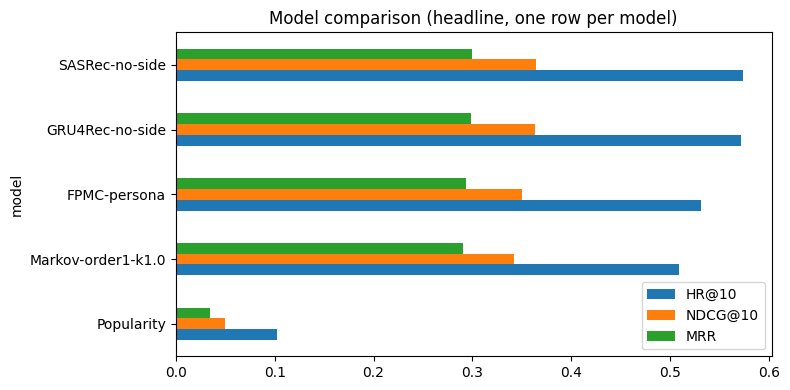


Ablation rows (not part of the headline ladder):


,HR@1,HR@5,HR@10,NDCG@5,NDCG@10,MRR,Accuracy@4,n_trips
model,,,,,,,,
FPMC-user,0.1922,0.4283,0.5151,0.3163,0.3445,0.2909,0.3949,70662
GRU4Rec-side,0.1711,0.4490,0.5664,0.3174,0.3555,0.2896,0.4080,70662
Markov-order1-k0.1,0.1933,0.4233,0.5090,0.3147,0.3425,0.2902,0.3905,70662
Markov-order1-k5.0,0.1933,0.4233,0.5090,0.3147,0.3425,0.2902,0.3905,70662
Markov-order2-k0.1,0.2108,0.3862,0.4438,0.3049,0.3236,0.2856,0.3646,70662
Markov-order2-k1.0,0.2108,0.3862,0.4438,0.3049,0.3236,0.2856,0.3646,70662
Markov-order2-k5.0,0.2108,0.3862,0.4438,0.3049,0.3236,0.2856,0.3646,70662
SASRec-side-concat,0.1516,0.3987,0.5169,0.2800,0.3183,0.2566,0.3617,70662
SASRec-side-sum,0.1806,0.4504,0.5715,0.3205,0.3597,0.2939,0.4097,70662


In [ ]:
res_all = (pd.read_csv(RESULTS)
             .drop_duplicates('model', keep='last')
             .set_index('model'))

def pick_preferred(prefix, prefer_substrings=()):
    """Find the best-matching row for a model family, preferring names that
    contain every string in `prefer_substrings`; falls back to the first
    match, or None if nothing matches at all."""
    candidates = [m for m in res_all.index if m.startswith(prefix)]
    for m in candidates:
        if all(s in m for s in prefer_substrings):
            return m
    return candidates[0] if candidates else None

preferred_markov = pick_preferred('Markov', prefer_substrings=('order1', 'k1.0'))
preferred_gru    = pick_preferred('GRU4Rec', prefer_substrings=('no-side',))
preferred_sasrec = pick_preferred('SASRec', prefer_substrings=('no-side',))

headline_models = ['Popularity']
headline_models += [m for m in (preferred_markov, 'FPMC-persona', preferred_gru, preferred_sasrec) if m]

res = res_all.reindex([m for m in headline_models if m in res_all.index])
display(res.round(4))

res[['HR@10', 'NDCG@10', 'MRR']].sort_values('NDCG@10').plot.barh(figsize=(8, 4))
plt.title('Model comparison (headline, one row per model)')
plt.tight_layout(); plt.show()

extra = res_all.index.difference(res.index)
if len(extra):
    print('\nAblation rows (not part of the headline ladder):')
    display(res_all.loc[extra].round(4))

Using any information about the trip is a huge jump over Popularity (0.05 → ~0.35). Among the real models the differences are small. The fancy neural models win at HR@10, but Markov actually has the best HR@1 (0.193, against 0.182 for GRU4Rec). So the neural models are better at "somewhere in the top 10" but not at "the very first guess".

## 3. Multi-seed re-runs -- is a gap between two models real, or a lucky seed?

FPMC/GRU4Rec/SASRec are all trained with random
embedding initialisation and random negative sampling, so a single run's score is one sample from a
noisy process, not a guaranteed number. Re-running each stochastic model across `SEEDS` and reporting
**mean +/- std** tells us whether a headline gap (e.g. FPMC-persona vs. FPMC-user) reflects the model
itself or just noise from where training happened to start.

Markov is excluded here -- it's built from pure counting with no randomness, so re-running it would
produce bit-for-bit identical results every time; `select_markov` (deterministic) is run once instead.

This cell also keeps each model's **seed-`REP_SEED` ranked lists**, so the sliced analyses below don't
need to retrain a fifth time -- they reuse exactly the predictions already produced here.

In [ ]:
def run_multiseed(run_fn, seeds, label, **kwargs):
    """Run `run_fn(data, seed=s, **kwargs)` for every seed.

    Returns (mean_metrics, std_metrics, {seed: ranked_lists}).
    """
    per_seed_metrics, per_seed_ranked = [], {}
    for s in seeds:
        metrics, ranked, val_ndcg = run_fn(data, seed=s, **kwargs)
        metrics = dict(metrics); metrics['seed'] = s
        per_seed_metrics.append(metrics)
        per_seed_ranked[s] = ranked
        print(f"  {label:<14} seed={s}  NDCG@10={metrics['NDCG@10']:.4f}  "
              f"HR@10={metrics['HR@10']:.4f}  train_secs={metrics.get('train_secs', '?')}")
    df = pd.DataFrame(per_seed_metrics).drop(columns=['seed'])
    numeric = df.select_dtypes(include=[np.number])
    return numeric.mean(), numeric.std(), per_seed_ranked


multiseed_results = {}   # model -> (mean_metrics, std_metrics)
ranked_rep = {}           # model -> ranked lists from the representative seed

print('--- FPMC (axis=persona) ---')
mean_m, std_m, ranked_m = run_multiseed(
    run_fpmc, SEEDS, 'FPMC-persona', axis='persona', epochs=20, verbose=False)
multiseed_results['FPMC-persona'] = (mean_m, std_m)
ranked_rep['FPMC-persona'] = ranked_m[REP_SEED]

print('--- Markov (order=1, smoothing=1.0, deterministic, single run) ---')
markov_metrics, markov_ranked, markov_val_ndcg = run_markov(
    data, order=1, smoothing=1.0, verbose=False)
print(f"  NDCG@10={markov_metrics['NDCG@10']:.4f}")
ranked_rep['Markov'] = markov_ranked

print('--- GRU4Rec (no side features) ---')
mean_m, std_m, ranked_m = run_multiseed(
    run_gru4rec, SEEDS, 'GRU4Rec-no-side', side_feats=(), epochs=40, device=DEVICE, verbose=False)
multiseed_results['GRU4Rec-no-side'] = (mean_m, std_m)
ranked_rep['GRU4Rec-no-side'] = ranked_m[REP_SEED]

print('--- SASRec (no side features) ---')
mean_m, std_m, ranked_m = run_multiseed(
    run_sasrec, SEEDS, 'SASRec-no-side', side_feats=(), epochs=40, device=DEVICE, verbose=False)
multiseed_results['SASRec-no-side'] = (mean_m, std_m)
ranked_rep['SASRec-no-side'] = ranked_m[REP_SEED]

--- FPMC (axis=persona) ---
  FPMC-persona   seed=1  NDCG@10=0.3456  HR@10=0.5310  train_secs=141.0
  FPMC-persona   seed=2  NDCG@10=0.3417  HR@10=0.5258  train_secs=137.3
  FPMC-persona   seed=3  NDCG@10=0.3452  HR@10=0.5269  train_secs=135.9
--- Markov (order=1, smoothing=1.0, deterministic, single run) ---
  NDCG@10=0.3425
--- GRU4Rec (no side features) ---
  GRU4Rec-no-side seed=1  NDCG@10=0.3493  HR@10=0.5582  train_secs=48.8
  GRU4Rec-no-side seed=2  NDCG@10=0.3586  HR@10=0.5673  train_secs=57.8
  GRU4Rec-no-side seed=3  NDCG@10=0.3597  HR@10=0.5706  train_secs=69.4
--- SASRec (no side features) ---
  SASRec-no-side seed=1  NDCG@10=0.3586  HR@10=0.5668  train_secs=180.7
  SASRec-no-side seed=2  NDCG@10=0.3660  HR@10=0.5794  train_secs=289.4
  SASRec-no-side seed=3  NDCG@10=0.3475  HR@10=0.5452  train_secs=132.0


In [ ]:
# mean +/- std summary table
METRIC_COLS = ['HR@1', 'HR@5', 'HR@10', 'NDCG@5', 'NDCG@10', 'MRR']

rows = []
for name, (mean_m, std_m) in multiseed_results.items():
    row = {'model': name}
    row.update({c: f"{mean_m[c]:.4f} +/- {std_m[c]:.4f}" for c in METRIC_COLS})
    rows.append(row)
rows.append({'model': 'Markov (deterministic)',
            **{c: f"{markov_metrics[c]:.4f} (n/a)" for c in METRIC_COLS}})

multiseed_df = pd.DataFrame(rows).set_index('model')
display(multiseed_df)

# save the full multi-seed summary (mean + std for every metric) to its own file,
# separate from results.csv, since results.csv is one-row-per-model by design
out_rows = []
for name, (mean_m, std_m) in multiseed_results.items():
    r = {'model': name, 'n_seeds': len(SEEDS)}
    for c in mean_m.index:
        r[f'{c}_mean'] = mean_m[c]; r[f'{c}_std'] = std_m[c]
    out_rows.append(r)
out_rows.append({'model': 'Markov', 'n_seeds': 1,
                 **{f'{c}_mean': markov_metrics[c] for c in METRIC_COLS},
                 **{f'{c}_std': 0.0 for c in METRIC_COLS}})
multiseed_path = os.path.join(ROOT, 'results_multiseed.csv')
pd.DataFrame(out_rows).to_csv(multiseed_path, index=False)
print('saved multi-seed summary to', multiseed_path)

,HR@1,HR@5,HR@10,NDCG@5,NDCG@10,MRR
model,,,,,,
FPMC-persona,0.1840 +/- 0.0027,0.4285 +/- 0.0061,0.5279 +/- 0.0027,0.3119 +/- 0.0033,0.3442 +/- 0.0021,0.2867 +/- 0.0022
GRU4Rec-no-side,0.1750 +/- 0.0032,0.4492 +/- 0.0070,0.5654 +/- 0.0064,0.3182 +/- 0.0059,0.3559 +/- 0.0057,0.2904 +/- 0.0054
SASRec-no-side,0.1828 +/- 0.0027,0.4453 +/- 0.0157,0.5638 +/- 0.0173,0.3190 +/- 0.0087,0.3574 +/- 0.0093,0.2931 +/- 0.0067
Markov (deterministic),0.1933 (n/a),0.4233 (n/a),0.5090 (n/a),0.3147 (n/a),0.3425 (n/a),0.2902 (n/a)


saved multi-seed summary to /content/SC4020-PROJECT1-main/results_multiseed.csv


GRU4Rec and SASRec are tied. Their gap (0.0015) is much smaller than the wobble between runs. SASRec's three runs ranged from 0.3475 to 0.3660.
FPMC and Markov are also basically tied.
Neural models beat Markov by about 0.013–0.015. That's a small but real edge.

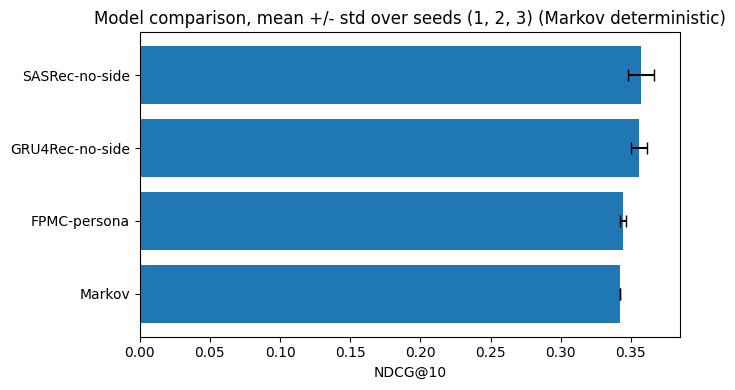

In [ ]:
# NDCG@10 with error bars (std across seeds; Markov has none, it's deterministic)
plot_rows = [{'model': n, 'mean': m['NDCG@10'], 'std': s['NDCG@10']}
            for n, (m, s) in multiseed_results.items()]
plot_rows.append({'model': 'Markov', 'mean': markov_metrics['NDCG@10'], 'std': 0.0})
pdf = pd.DataFrame(plot_rows).set_index('model').sort_values('mean')

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(pdf.index, pdf['mean'], xerr=pdf['std'], capsize=4)
ax.set_xlabel('NDCG@10')
ax.set_title(f'Model comparison, mean +/- std over seeds {SEEDS} (Markov deterministic)')
plt.tight_layout(); plt.show()

SASRec has the widest whisker. Its three runs were 0.3586, 0.3660 and 0.3475, so it's the least stable. FPMC is the most stable.
GRU4Rec vs SASRec: the ranges almost completely overlap, so they're tied.
FPMC vs Markov: Markov's 0.3425 falls inside FPMC's range, so they're tied.
Neural vs Markov: GRU4Rec's mean is about 2.4 stds above Markov, which is fairly convincing. SASRec's is only about 1.6 stds above, so it's weaker evidence.
Only 3 seeds were used, so the std values are themselves rough guesses. Treat these conclusions as suggestive, not proven.

## 4. Sliced by trip length -- the project's central hypothesis

Does long-range memory (GRU4Rec, SASRec) actually pay off on longer trips, while the simpler models
stay competitive on short ones? This reuses the `ranked_rep` predictions already produced above --
no retraining.

,<=3,4-5,6+
model,,,
FPMC-persona,0.3517,0.3380,0.3415
Markov,0.3320,0.3520,0.3568
GRU4Rec-no-side,0.3653,0.3352,0.3274
SASRec-no-side,0.3703,0.3452,0.3483


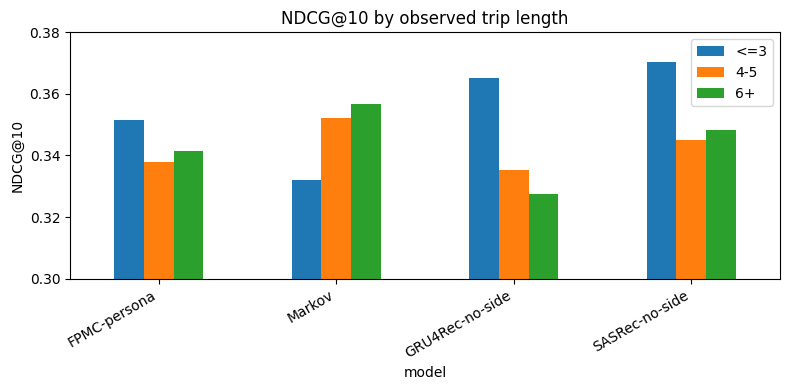

In [ ]:
targets = [t['target_city'] for t in data['test']]

def length_group(t):
    n = len(t['cities'])
    return '<=3' if n <= 3 else ('4-5' if n <= 5 else '6+')

length_groups = [length_group(t) for t in data['test']]

length_rows = []
for name, ranked in ranked_rep.items():
    sl = evaluate_sliced(ranked, targets, length_groups)
    row = {'model': name}
    row.update({g: m['NDCG@10'] for g, m in sl.items()})
    length_rows.append(row)

length_df = pd.DataFrame(length_rows).set_index('model')
length_df = length_df[[c for c in ['<=3', '4-5', '6+'] if c in length_df.columns]]
display(length_df.round(4))

length_df.plot.bar(figsize=(8, 4))
plt.ylabel('NDCG@10'); plt.title('NDCG@10 by observed trip length')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.ylim(0.30, 0.38); plt.show()

The hypothesis was not supported, and the pattern is the opposite. The neural models do best on short trips, and Markov is best on long ones. Plausible explanation: most training
  positions come from short prefixes, so long-context examples are comparatively rare
  during training, while Markov is length-invariant by construction (it only ever
  looks at the last city). Let's test this explanation next:

In [6]:
from collections import Counter
lengths = Counter(len(t['cities']) for t in data['train'])
for n in sorted(lengths):
    print(n, lengths[n])

2 4689
3 16133
4 77389
5 39074
6 21611
7 12634
8 7416
9 4342
10 2806
11 1710
12 1082
13 649
14 444
15 263
16 154
17 91
18 66
19 52
20 38
21 24
22 20
23 13
24 12
25 7
26 4
27 3
28 1
29 1
30 1
31 1
32 2
34 1
39 3
40 1


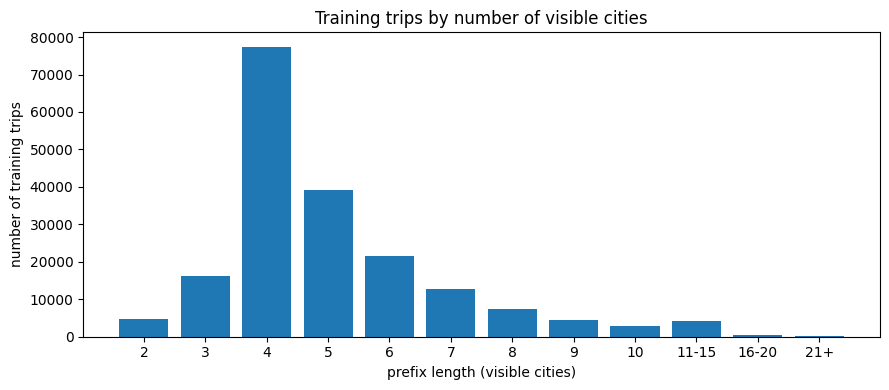

<=3: 20822 (10.9%)
4-5: 116463 (61.1%)
6+:  53452 (28.0%)


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# lengths -> counts, from your printed distribution
length_counts = {
    2:4689, 3:16133, 4:77389, 5:39074, 6:21611, 7:12634, 8:7416, 9:4342, 10:2806,
    11:1710, 12:1082, 13:649, 14:444, 15:263, 16:154, 17:91, 18:66, 19:52, 20:38,
    21:24, 22:20, 23:13, 24:12, 25:7, 26:4, 27:3, 28:1, 29:1, 30:1, 31:1, 32:2,
    34:1, 39:3, 40:1
}

# bucket into the same bins used for readability (2..10 individually, then wider bins)
def bucket(n):
    if n <= 10: return str(n)
    if n <= 15: return '11-15'
    if n <= 20: return '16-20'
    return '21+'

binned = {}
for n, count in length_counts.items():
    b = bucket(n)
    binned[b] = binned.get(b, 0) + count

order = [str(i) for i in range(2, 11)] + ['11-15', '16-20', '21+']
counts = [binned.get(b, 0) for b in order]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(order, counts)
ax.set_xlabel('prefix length (visible cities)')
ax.set_ylabel('number of training trips')
ax.set_title('Training trips by number of visible cities')
plt.tight_layout(); plt.show()

# also print the <=3 / 4-5 / 6+ split, matching your slicing buckets
total = sum(length_counts.values())
le3 = sum(v for k, v in length_counts.items() if k <= 3)
b45 = sum(v for k, v in length_counts.items() if 4 <= k <= 5)
b6p = sum(v for k, v in length_counts.items() if k >= 6)
print(f"<=3: {le3} ({le3/total:.1%})")
print(f"4-5: {b45} ({b45/total:.1%})")
print(f"6+:  {b6p} ({b6p/total:.1%})")

As expected, training is heavily concentrated in the 4-5 stop range (61% of trips); the 6+ bucket, while not negligible (28%), spans a long, thin tail — trips of 15+ stops number in the dozens or fewer, so whatever signal genuinely long sequences carry is diluted by the much larger short/medium-length population dominating training.

Markov's absolute score rises with trip length (0.332 → 0.352 → 0.357). It's not "surviving" the 6+ bucket, it's actually best there. GRU4Rec's absolute score falls with length (0.365 → 0.335 → 0.327) — the clearest monotonic decline in the table. SASRec dips in the middle bucket then partially recovers, staying flat-ish rather than declining.

The neural models' edge comes from patterns learned on the length range they saw the most of (4-5), and that edge specifically erodes as trips move away from that center — while Markov, being length-invariant by construction (it only ever looks at the last city), has no such center to drift away from.

## 5. Sliced by destination popularity -- head vs. tail

Cities are bucketed by how often they appear in **training** (`head` = top 10% most-visited,
`tail` = bottom 50% least-visited, `mid` = in between). The hypothesis: Markov's pure counting
should do fine on head destinations but degrade on the tail, while embedding-based models
(FPMC/GRU4Rec/SASRec), which can generalise across similar cities rather than only matching exact
contexts, should hold up better on rare destinations.

,head,mid,tail
model,,,
FPMC-persona,0.3998,0.0012,0.0000
Markov,0.3910,0.0402,0.0136
GRU4Rec-no-side,0.4009,0.0271,0.0017
SASRec-no-side,0.4133,0.0133,0.0002


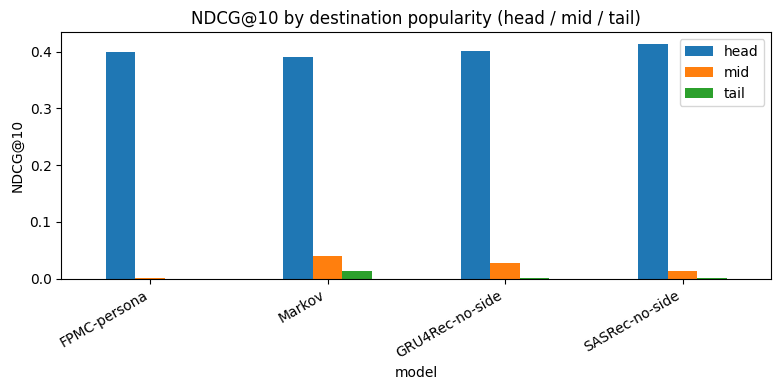

In [ ]:
freq = city_frequency(data)
q50, q90 = np.quantile(freq[freq > 0], [0.5, 0.9])

def pop_group(tgt):
    f = freq[tgt]
    return 'head' if f >= q90 else ('tail' if f <= q50 else 'mid')

pop_groups = [pop_group(t) for t in targets]

pop_rows = []
for name, ranked in ranked_rep.items():
    sl = evaluate_sliced(ranked, targets, pop_groups)
    row = {'model': name}
    row.update({g: m['NDCG@10'] for g, m in sl.items()})
    pop_rows.append(row)

pop_df = pd.DataFrame(pop_rows).set_index('model')
pop_df = pop_df[[c for c in ['head', 'mid', 'tail'] if c in pop_df.columns]]
display(pop_df.round(4))

pop_df.plot.bar(figsize=(8, 4))
plt.ylabel('NDCG@10'); plt.title('NDCG@10 by destination popularity (head / mid / tail)')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

Every model is basically only good at guessing popular cities. Nearly all the score comes from the head column.
The hypothesis that embeddings handle rare cities better was also not supported. Markov is the best on mid and tail, though everything is close to zero there.

In [13]:
import numpy as np
from src.evaluate import city_frequency

freq = city_frequency(data)
sample_negs = np.random.randint(2, data['n_cities'], size=100000)
print('median training frequency of a random negative:', np.median(freq[sample_negs]))
print('median training frequency of a real target city:', np.median(freq[freq > 0]))

median training frequency of a random negative: 3.0
median training frequency of a real target city: 3.0


A city seen 3 times in training gives any model — however it's trained — very little to learn a reliable transition pattern from, regardless of how negatives are sampled.

## 6. Efficiency -- accuracy vs. cost

**Note:** `evaluate.py`'s `append_result` only writes the fixed columns in `RESULT_COLUMNS`
(`HR@k`, `NDCG@k`, `MRR`, `Accuracy@4`, `n_trips`) -- `train_secs`, `n_params` and Markov's
`fallback_rate` are **not** persisted to `results.csv`, even though every `run_*` function returns
them. So this section pulls those numbers from the metrics dictionaries already sitting in memory
from the multi-seed runs above, rather than reading them back out of `results.csv` (they aren't
there to read).

,NDCG@10,train_secs,n_params
model,,,
FPMC-persona,0.3442,138.0667,7662784.0
GRU4Rec-no-side,0.3559,58.6667,2582656.0
SASRec-no-side,0.3574,200.7000,2655168.0
Markov,0.3425,13.9000,276426.0


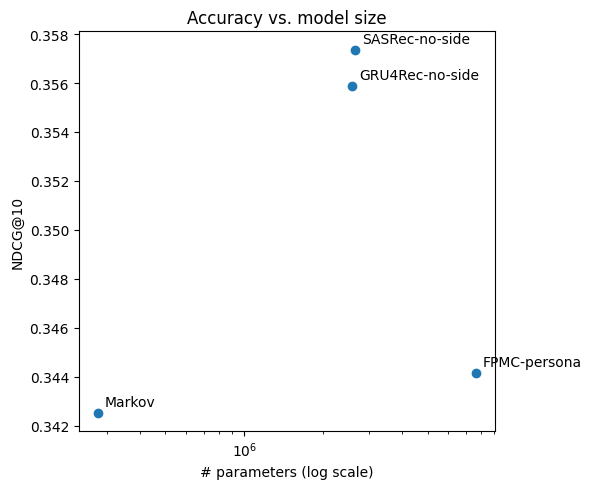


Markov fallback rate on test: 0.4%
Markov selected config:(order=1, smoothing=1.0)
(fallback = fraction of test trips whose context was never seen at the selected order -- the single number that explains Markov's ceiling.)


In [ ]:
eff_rows = []
for name, (mean_m, std_m) in multiseed_results.items():
    eff_rows.append({'model': name, 'NDCG@10': mean_m['NDCG@10'],
                     'train_secs': mean_m['train_secs'], 'n_params': mean_m['n_params']})
eff_rows.append({'model': 'Markov', 'NDCG@10': markov_metrics['NDCG@10'],
                 'train_secs': markov_metrics['train_secs'],
                 'n_params': markov_metrics['n_params']})

eff_df = pd.DataFrame(eff_rows).set_index('model')
display(eff_df.round(4))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(eff_df['n_params'], eff_df['NDCG@10'])
for name, row in eff_df.iterrows():
    ax.annotate(name, (row['n_params'], row['NDCG@10']),
               textcoords='offset points', xytext=(5, 5))
ax.set_xscale('log')
ax.set_xlabel('# parameters (log scale)'); ax.set_ylabel('NDCG@10')
ax.set_title('Accuracy vs. model size'); plt.tight_layout(); plt.show()

print(f"\nMarkov fallback rate on test: {markov_metrics.get('fallback_rate', float('nan')):.1%}")
print(f"Markov selected config:(order=1, smoothing=1.0)")
print("(fallback = fraction of test trips whose context was never seen at the selected order --"
     " the single number that explains Markov's ceiling.)")

Note: FPMC was run on CPU while GRU4Rec/SASRec were run on GPU

1. FPMC is the worst value in the table
FPMC costs almost 10x Markov's training time (138s vs 14s) and 28x its parameter count (7.66M vs 276k), for an accuracy gain of 0.0017 NDCG@10 — a difference we already established is inside the noise. FPMC is paying a massive cost premium for a tie. If you were deploying one of these two, Markov is strictly better on the accuracy-vs-cost tradeoff: same accuracy, a fraction of the compute, and (unlike FPMC) fully interpretable counts rather than opaque embeddings.

2. GRU4Rec is the best value in the table
It reaches essentially the same accuracy as SASRec (0.3559 vs 0.3574, tied) while costing roughly 3.4x less training time (58.7s vs 200.7s) and having slightly fewer parameters. If the two are statistically indistinguishable on accuracy, GRU4Rec is the more efficient choice between them.

## 7. Bonus: bootstrap confidence intervals -- is the *test-set* gap signal or noise?

Multi-seed (section 3) captures **training** variance -- was this a lucky initialisation? Bootstrap
captures a different uncertainty: **evaluation** variance -- did we happen to test on an easy or hard
slice of trips? We resample which test trips get scored (with replacement) many times and see how
much each model's NDCG@10 wobbles. This uses the same `ranked_rep` predictions from section 3/4/5,
so no retraining is needed here either.

Bootstrap 95% CI on NDCG@10 (n_boot=200 resamples per model; increase for a tighter CI):
  FPMC-persona NDCG@10 = 0.3457  95% CI [0.3430, 0.3481]
  Markov     NDCG@10 = 0.3425  95% CI [0.3398, 0.3455]
  GRU4Rec-no-side NDCG@10 = 0.3494  95% CI [0.3470, 0.3522]
  SASRec-no-side NDCG@10 = 0.3586  95% CI [0.3560, 0.3613]


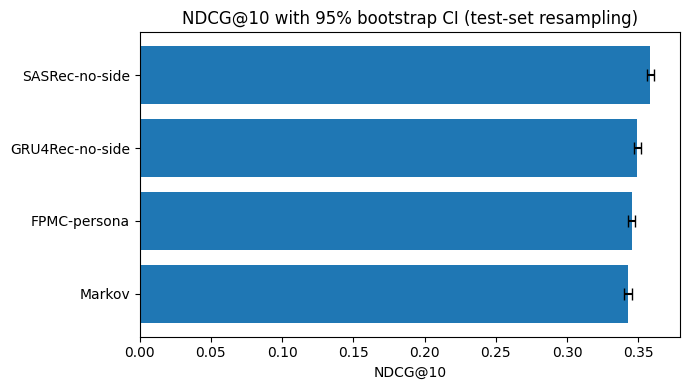


If two models' CIs overlap substantially, the gap between them may not be a reliable difference given this test set -- say so explicitly rather than over-claiming a ranking.


In [ ]:
def bootstrap_ci(ranked, targets, metric='NDCG@10', n_boot=200, seed=0):
    rng = np.random.default_rng(seed)
    n = len(targets)
    ranked = list(ranked); targets = list(targets)
    vals = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        r = [ranked[j] for j in idx]
        t = [targets[j] for j in idx]
        vals[i] = evaluate(r, t)[metric]
    return vals.mean(), np.percentile(vals, [2.5, 97.5])

print('Bootstrap 95% CI on NDCG@10 (n_boot=200 resamples per model; increase for a tighter CI):')
boot_rows = []
for name, ranked in ranked_rep.items():
    mean, (lo, hi) = bootstrap_ci(ranked, targets, metric='NDCG@10', n_boot=200)
    boot_rows.append({'model': name, 'NDCG@10_mean': mean, 'ci_low': lo, 'ci_high': hi})
    print(f"  {name:<10} NDCG@10 = {mean:.4f}  95% CI [{lo:.4f}, {hi:.4f}]")

boot_df = pd.DataFrame(boot_rows).set_index('model').sort_values('NDCG@10_mean')
fig, ax = plt.subplots(figsize=(7, 4))
yerr = np.vstack([boot_df['NDCG@10_mean'] - boot_df['ci_low'],
                  boot_df['ci_high'] - boot_df['NDCG@10_mean']])
ax.barh(boot_df.index, boot_df['NDCG@10_mean'], xerr=yerr, capsize=4)
ax.set_xlabel('NDCG@10'); ax.set_title('NDCG@10 with 95% bootstrap CI (test-set resampling)')
plt.tight_layout(); plt.show()

print("\nIf two models' CIs overlap substantially, the gap between them may not be a reliable"
     " difference given this test set -- say so explicitly rather than over-claiming a ranking.")

* Markov and FPMC are indistinguishable here too — same conclusion as the
multi-seed check. Their CIs overlap substantially, so there's no basis for saying persona-based personalization beats a plain order-1 transition table.
* SASRec is clearly separated from everyone — its CI doesn't touch any other model's. On this specific test-set resampling, SASRec's edge over both GRU4Rec and the lower tier looks real, not noise.
* GRU4Rec is clearly above Markov (no CI overlap), and only barely overlaps FPMC at the very edges. So GRU4Rec vs. Markov is a real gap; GRU4Rec vs. FPMC is close to a tie, tilting toward GRU4Rec.

Bootstrap resampling of the test set shows SASRec's advantage over GRU4Rec is consistent within a single trained model (non-overlapping 95% CIs), while multi-seed retraining shows SASRec's outcome is itself more variable across random initializations than GRU4Rec's (std 0.0093 vs 0.0057). Together, these suggest SASRec has a real per-run edge but is a less reliably-trained model than GRU4Rec — a genuine cost/reliability tradeoff, not just an accuracy question.

## 8. What to write up

- **Headline ladder:** report the curated table from section 2, and note which multi-seed means
  (section 3) each row actually reflects (e.g. "SASRec: 0.xxxx +/- 0.00yy over 3 seeds").
- **Multi-seed vs. bootstrap -- two different uncertainties:** multi-seed (section 3) asks "was
  training lucky?"; bootstrap (section 7) asks "was the test split easy?". Report both, and be
  explicit when a headline gap's multi-seed std or bootstrap CI is large relative to the gap itself
  -- that gap should be described as suggestive, not conclusive.
- **Trip length (section 4):** this is the project's central hypothesis test. State plainly whether
  GRU4Rec/SASRec's advantage over Markov/FPMC actually grows on longer trips, or whether it doesn't
  -- either answer is a real finding.
- **Popularity slicing (section 5):** state whether embedding-based models actually hold up better
  than Markov on tail destinations, which is the concrete, testable version of "embeddings
  generalise, lookup tables don't."
- **Fallback rate (section 6):** Markov's fallback rate is the direct, quantified explanation for
  its ceiling -- pair it with the trip-length/popularity slices where Markov specifically falls
  behind.
- **Efficiency (section 6):** report the accuracy-vs-#params trade-off plot -- a real comparison has
  to weigh whether SASRec's likely edge over GRU4Rec (if any) is worth its extra parameters/training
  time for this specific task.
- **Sanity peg (section 1):** state explicitly that Popularity's Accuracy@4 reproduced the ~0.053
  reference, and by how much, as evidence the scoring pipeline is correct.